# Early dyslexia screening from children's handwriting

**ALU BSE: Machine Learning Pipeline summative**
Author: Beulla Jeanne Francoise Rugero

## Why this project

My Introduction to Machine Learning project ([model_training_and_evaluation](https://github.com/Beulla/model_training_and_evaluation)) used the tabular OULAD dataset to **identify at-risk learners early**, so support reaches them before they fail or withdraw. It is part of a wider mission: building safe havens for children from unstable homes by spotting vulnerable people early.

This pipeline keeps that goal and moves to **non-tabular data**: **images of single handwritten characters** written by children aged 6–10. The model flags handwriting that matches the pattern of children with dyslexia. Children with dyslexia are much more likely to struggle and drop behind if nobody notices, and a quick handwriting screen can tell a teacher whom to refer for a full assessment.

> Screening aid for education research. It does **not** diagnose dyslexia.

## Pipeline in this notebook
1. Data acquisition
2. Data processing (image preprocessing + three interpretable features)
3. Model creation (baseline CNN vs transfer learning)
4. Model training
5. Model testing (accuracy, precision, recall, F1, sensitivity, specificity, ROC-AUC, confusion matrix)
6. Prediction function
7. Retraining (warm start + quality gate) and its trigger

The same `src/` code is used by the deployed API (`api/main.py`) and UI (`ui/app.py`).

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

sns.set_theme(style="whitegrid")
torch.manual_seed(42); np.random.seed(42)
COLORS = {"Non-dyslexic": "#2a9d8f", "Dyslexic (at risk)": "#e76f51"}
print("Project root:", ROOT)
print("PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Project root: C:\Users\HP Spectre\Projects\alu-ml-summative-diabetes
PyTorch 2.15.0+cpu


## 1. Data acquisition

**Dataset:** *Multilingual AI-Based Dyslexia Detection*, Mendeley Data, DOI [10.17632/b37s8b94nv.1](https://doi.org/10.17632/b37s8b94nv.1), CC BY 4.0.

- 852 character-level handwriting images (English letters, Urdu letters, digits 0–9)
- 100 children aged 6–10 in school settings in Narowal, Punjab, Pakistan
- 426 images from the dyslexic group (`Yes`) and 426 from the non-dyslexic group (`No`)
- Phone photos (iPhone 11) of pencil-on-paper writing, at many different resolutions

`scripts/prepare_data.py` downloads the zip, checks its SHA-256 checksum, makes a **stratified 80/20 train/test split** (seed 42), preprocesses every image and writes:

```
data/train/{non_dyslexic,dyslexic}/*.png
data/test/{non_dyslexic,dyslexic}/*.png
```

In [2]:
from src.config import CLASS_NAMES, TRAIN_DIR, TEST_DIR, RAW_DIR
from src.preprocessing import dataset_counts, iter_labelled_images

if sum(1 for _ in iter_labelled_images(TRAIN_DIR)) == 0:
    import runpy
    runpy.run_path(str(ROOT / "scripts" / "prepare_data.py"), run_name="__main__")

counts = pd.DataFrame({"train": dataset_counts(TRAIN_DIR), "test": dataset_counts(TEST_DIR)})
counts.loc["total"] = counts.sum()
counts["total"] = counts.sum(axis=1)
counts

,train,test,total
Non-dyslexic,340,86,426
Dyslexic (at risk),341,85,426
total,681,171,852


## 2. Data processing

### 2.1 Image preprocessing

The raw images are phone photos, so they vary in size, orientation, lighting and paper colour. If we fed them in as-is, the model could learn *"darker photo → dyslexic"* instead of anything about handwriting. `src/preprocessing.preprocess_image` applies the same steps to every image (training, test, uploads and live predictions):

| Step | Why |
|---|---|
| EXIF orientation fix | phone photos are stored rotated |
| Grayscale | pencil on paper carries no useful colour |
| Auto-contrast (1 % cut-off) | removes lighting / paper-colour differences between photos |
| Pad to square with the paper colour | keeps the letter's real proportions (squashing would distort the shape) |
| Resize to 128 × 128 | fixed input size for the CNN |

At training time the model also gets **augmentation**: small rotations, shifts, scaling, and brightness/contrast jitter. It gets **no horizontal or vertical flips**, because a mirrored letter is exactly the reversal error typical of dyslexia, and flipping would corrupt the labels.

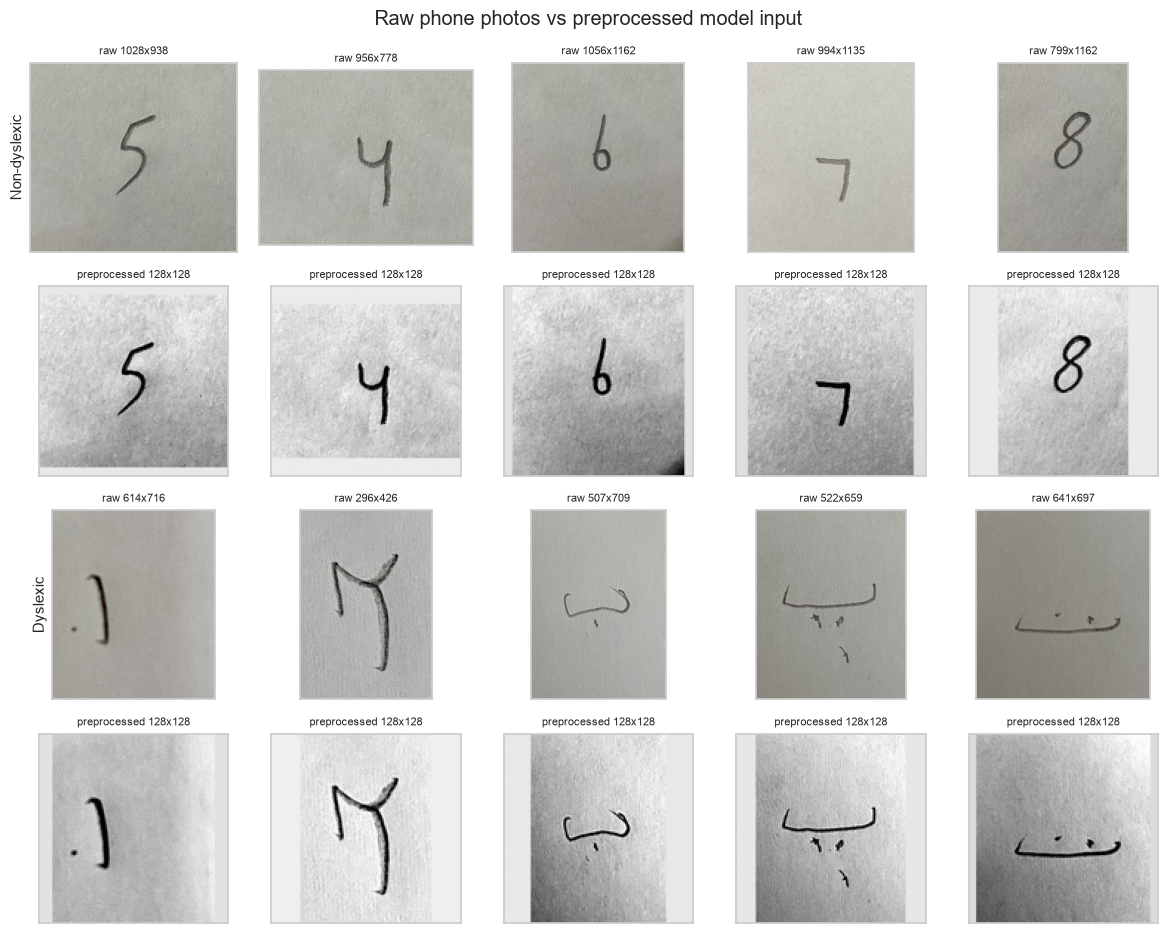

In [3]:
import zipfile
from io import BytesIO
from PIL import Image, ImageOps
from src.preprocessing import preprocess_image

zip_path = RAW_DIR / "dyslexia_handwriting.zip"
with zipfile.ZipFile(zip_path) as zf:
    members = {c: sorted(n for n in zf.namelist() if f"/{c}/" in n and n[-1] != "/")[:5] for c in ("No", "Yes")}
    fig, axes = plt.subplots(4, 5, figsize=(12, 9.5))
    for r, (cls, names) in enumerate(members.items()):
        for c, name in enumerate(names):
            raw = ImageOps.exif_transpose(Image.open(BytesIO(zf.read(name))))
            axes[2 * r, c].imshow(raw.convert("RGB")); axes[2 * r, c].set_title(f"raw {raw.size[0]}x{raw.size[1]}", fontsize=8)
            axes[2 * r + 1, c].imshow(preprocess_image(raw), cmap="gray", vmin=0, vmax=255)
            axes[2 * r + 1, c].set_title("preprocessed 128x128", fontsize=8)
        axes[2 * r, 0].set_ylabel("Non-dyslexic" if cls == "No" else "Dyslexic", fontsize=11)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Raw phone photos vs preprocessed model input")
plt.tight_layout(); plt.show()

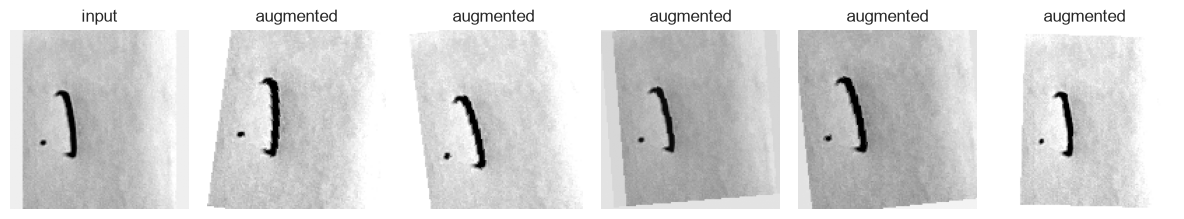

In [4]:
import random
from src.model import train_transforms

sample_path = next(iter_labelled_images(TRAIN_DIR))[0]
from src.preprocessing import load_image
img = load_image(sample_path)
tfm = train_transforms()
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("input")
for ax in axes[1:]:
    t = tfm(img)[0] * 0.229 + 0.485   # undo normalisation of one channel for display
    ax.imshow(t.numpy(), cmap="gray", vmin=0, vmax=1); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.2 Three interpretable features and the story they tell

To understand the data, not just to train on it, `extract_image_features` computes simple handwriting measurements on each preprocessed image. The ink mask is every pixel darker than halfway between the paper colour (median) and the ink colour (darkest 1 %).

| Feature | Computation | What it captures |
|---|---|---|
| **Ink coverage** | ink pixels ÷ all pixels | size and heaviness of the letter |
| **Stroke darkness** | (paper mean − ink mean) ÷ 255 | pen pressure |
| **Stroke thinness** | stroke-edge pixels ÷ ink pixels | thin confident strokes (high) vs thick, retraced strokes (low) |

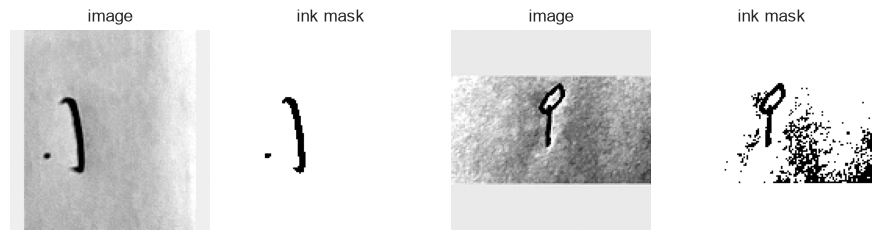

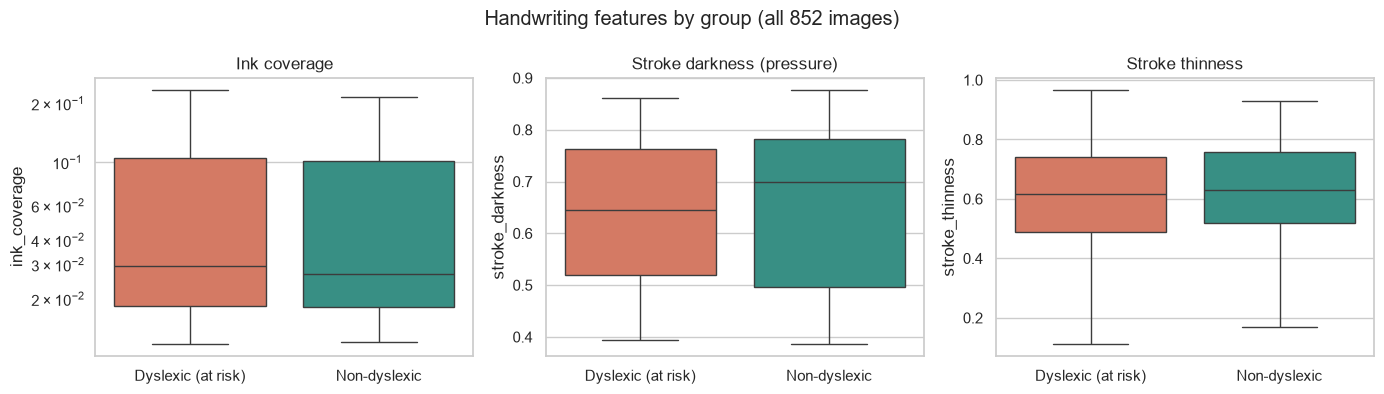

,feature,median dyslexic,median non-dyslexic,single-feature AUC,Mann-Whitney p
0,Ink coverage,0.0295,0.0269,0.5239,0.2275
1,Stroke darkness (pressure),0.6460,0.6996,0.4847,0.4397
2,Stroke thinness,0.6171,0.6308,0.4654,0.0804


In [5]:
from src.preprocessing import build_feature_table, ink_mask
from scipy.stats import mannwhitneyu

feats = build_feature_table()
feats["group"] = feats["label_name"]
FEATS = {"ink_coverage": "Ink coverage", "stroke_darkness": "Stroke darkness (pressure)", "stroke_thinness": "Stroke thinness"}

# What the ink mask sees
fig, axes = plt.subplots(1, 4, figsize=(9, 2.4))
for ax, (p, _) in zip(axes[::2], list(iter_labelled_images(TRAIN_DIR))[:400:200]):
    g = np.asarray(load_image(p), dtype=np.float32)
    ax.imshow(g, cmap="gray"); ax.set_title("image"); ax.axis("off")
for ax, (p, _) in zip(axes[1::2], list(iter_labelled_images(TRAIN_DIR))[:400:200]):
    g = np.asarray(load_image(p), dtype=np.float32)
    ax.imshow(ink_mask(g), cmap="gray_r"); ax.set_title("ink mask"); ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, name) in zip(axes, FEATS.items()):
    sns.boxplot(data=feats, x="group", y=col, hue="group", palette=COLORS, ax=ax, showfliers=False, legend=False)
    ax.set_title(name); ax.set_xlabel("")
    if col == "ink_coverage": ax.set_yscale("log")
plt.suptitle("Handwriting features by group (all 852 images)"); plt.tight_layout(); plt.show()

rows = []
for col, name in FEATS.items():
    a, b = feats.loc[feats.label == 1, col], feats.loc[feats.label == 0, col]
    u, p = mannwhitneyu(a, b)
    rows.append({"feature": name, "median dyslexic": a.median(), "median non-dyslexic": b.median(),
                 "single-feature AUC": u / (len(a) * len(b)), "Mann-Whitney p": p})
pd.DataFrame(rows).round(4)

**Interpretation**

1. **Ink coverage.** Letters from the dyslexic group cover slightly more of the frame. That fits larger, less controlled letter forms and over-writing.
2. **Stroke darkness (pen pressure).** The dyslexic group writes a little lighter (median ≈ 0.65 vs 0.70). Uneven, light pressure is a known feature of effortful handwriting.
3. **Stroke thinness.** The dyslexic group's strokes are thicker or retraced (lower score; p ≈ 0.08). This fits children going back over letters they are unsure of.

**The story.** All three differences point the same way, toward *effortful, less automatic writing*. But the distributions **overlap almost completely**: each feature on its own separates the groups barely better than a coin flip (AUC 0.47–0.54). Dyslexia does not show up as a simple ink statistic. It shows up in the **shape** of letters: reversals (b/d, p/q, mirrored digits), malformed strokes, odd proportions. That is the case for a convolutional network, which learns shape directly from pixels.

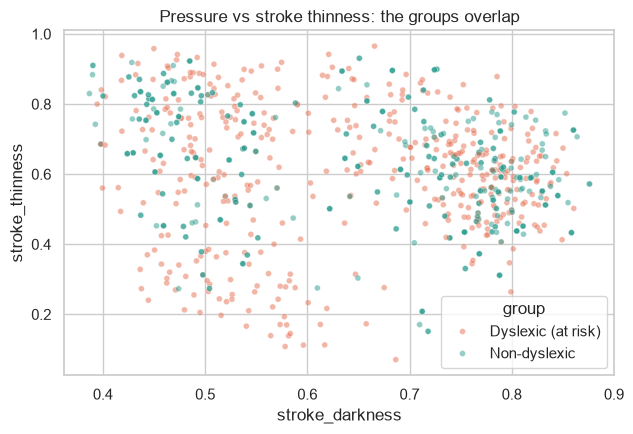

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(data=feats, x="stroke_darkness", y="stroke_thinness", hue="group", palette=COLORS, alpha=0.5, s=18, ax=ax)
ax.set_title("Pressure vs stroke thinness: the groups overlap"); plt.tight_layout(); plt.show()

## 3. Model creation

Two models are compared:

* **Baseline: `SimpleCNN`**, 4 conv blocks (Conv-BatchNorm-ReLU-MaxPool), global average pooling and dropout, trained **from scratch**.
* **Production: `MobileNetV3-Small`** pre-trained on ImageNet (**transfer learning**), with a new 2-class head. Its early layers already detect edges, curves and stroke junctions, which is valuable with only ~700 training images.

Optimisation techniques used in `src/model.py`:
- Adam with weight decay (L2 regularisation, 1e-4)
- full fine-tuning of the pre-trained backbone (chosen by the experiment below)
- `ReduceLROnPlateau` on validation F1
- **early stopping** with best-checkpoint restore (patience 6)
- class-weighted cross-entropy (stays fair if uploads unbalance the classes)
- dropout + data augmentation
- 15 % stratified validation split carved out of `data/train` (the test set is never touched during training)

**Learning-rate experiment** (MobileNetV3, same data, test set):

| Backbone learning rate | Head lr | Epochs | Accuracy | Macro F1 | ROC-AUC |
|---|---|---|---|---|---|
| head lr ÷ 10 (mostly frozen features) | 1e-3 | 20 (early stop) | 0.637 | 0.620 | 0.742 |
| head lr ÷ 3 | 1e-3 | 30 | 0.801 | 0.801 | 0.861 |
| **same as head (full fine-tuning)** | **5e-4** | **30** | **0.807** | **0.807** | **0.877** |

Handwriting photos look very different from ImageNet photos, so the backbone has to adapt fully. A nearly frozen backbone leaves the model guessing on most of the non-dyslexic group (specificity 0.42).

In [7]:
from src.model import build_model

for arch in ("simple_cnn", "mobilenet_v3_small"):
    m = build_model(arch)
    n = sum(p.numel() for p in m.parameters())
    print(f"{arch:20s} parameters: {n:,}")

simple_cnn           parameters: 60,994


mobilenet_v3_small   parameters: 1,519,906


## 4. Model training

### 4.1 Baseline CNN from scratch

In [8]:
from src.config import MODELS_DIR
from src.model import train_model, evaluate_model

baseline, base_hist = train_model(TRAIN_DIR, epochs=30, lr=1e-3, arch="simple_cnn", verbose=False,
                                  model_path=MODELS_DIR / "candidate" / "baseline_simple_cnn.pt")
base_metrics = evaluate_model(baseline, TEST_DIR, out_path=None)
print({k: round(base_metrics[k], 3) for k in ("accuracy", "f1_macro", "roc_auc")})

{'accuracy': 0.596, 'f1_macro': 0.596, 'roc_auc': 0.683}


### 4.2 Transfer-learning model (production)

`src.train.run_training` is the **same function** the API calls for retraining. It trains, evaluates on the held-out test set, and saves:

* `models/dyslexia_cnn.pt`: PyTorch weights + metadata
* `models/dyslexia_cnn.pkl`: the same payload as a pickle (joblib)
* `models/eval_metrics.json`, `models/model_meta.json`

In [9]:
from src.train import run_training

result = run_training()          # initial training (no warm start)
metrics = result["metrics"]
print("saved:", result["model_path"])
print({k: round(metrics[k], 3) for k in ("accuracy", "f1_macro", "roc_auc")})

epoch  1/30  loss=0.687 acc=0.563  val_loss=0.724 val_acc=0.480 val_f1=0.476


epoch  2/30  loss=0.624 acc=0.661  val_loss=0.633 val_acc=0.676 val_f1=0.673


epoch  3/30  loss=0.551 acc=0.712  val_loss=0.673 val_acc=0.608 val_f1=0.602


epoch  4/30  loss=0.529 acc=0.736  val_loss=0.695 val_acc=0.578 val_f1=0.578


epoch  5/30  loss=0.491 acc=0.737  val_loss=0.588 val_acc=0.686 val_f1=0.674


epoch  6/30  loss=0.455 acc=0.791  val_loss=0.650 val_acc=0.686 val_f1=0.684


... (21 outputs left out)

epoch 28/30  loss=0.135 acc=0.945  val_loss=0.525 val_acc=0.814 val_f1=0.814


epoch 29/30  loss=0.162 acc=0.922  val_loss=0.536 val_acc=0.814 val_f1=0.814


epoch 30/30  loss=0.148 acc=0.948  val_loss=0.551 val_acc=0.814 val_f1=0.814


saved: C:\Users\HP Spectre\Projects\alu-ml-summative-diabetes\models\dyslexia_cnn.pt
{'accuracy': 0.807, 'f1_macro': 0.807, 'roc_auc': 0.877}


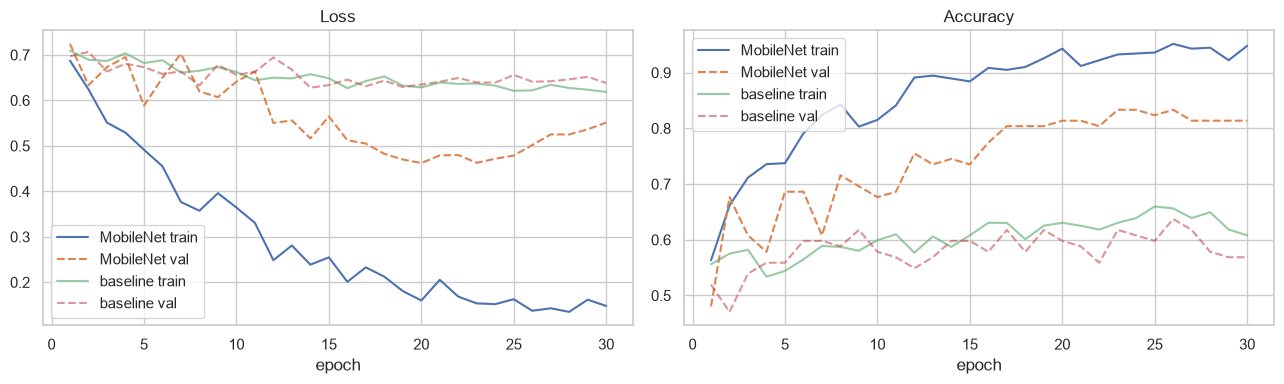

In [10]:
from src.config import MODEL_META_PATH
meta = json.loads(MODEL_META_PATH.read_text())
h = pd.DataFrame(meta["history"]); h.index += 1
bh = pd.DataFrame(base_hist); bh.index += 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(h["loss"], label="MobileNet train"); axes[0].plot(h["val_loss"], "--", label="MobileNet val")
axes[0].plot(bh["loss"], label="baseline train", alpha=0.6); axes[0].plot(bh["val_loss"], "--", label="baseline val", alpha=0.6)
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["accuracy"], label="MobileNet train"); axes[1].plot(h["val_accuracy"], "--", label="MobileNet val")
axes[1].plot(bh["accuracy"], label="baseline train", alpha=0.6); axes[1].plot(bh["val_accuracy"], "--", label="baseline val", alpha=0.6)
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Model testing: full metric set on the held-out test set (171 images, never seen in training)

In [11]:
from src.model import load_trained_model
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

prod = load_trained_model()
prod_metrics = evaluate_model(prod, TEST_DIR, out_path=None)

keys = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
        "sensitivity_at_risk", "specificity", "roc_auc"]
comparison = pd.DataFrame({"Baseline CNN (scratch)": {k: base_metrics[k] for k in keys},
                           "MobileNetV3 (transfer)": {k: prod_metrics[k] for k in keys}}).round(3)
comparison

,Baseline CNN (scratch),MobileNetV3 (transfer)
accuracy,0.596,0.807
precision_macro,0.596,0.809
recall_macro,0.596,0.807
f1_macro,0.596,0.807
f1_weighted,0.596,0.807
sensitivity_at_risk,0.588,0.765
specificity,0.605,0.849
roc_auc,0.683,0.877


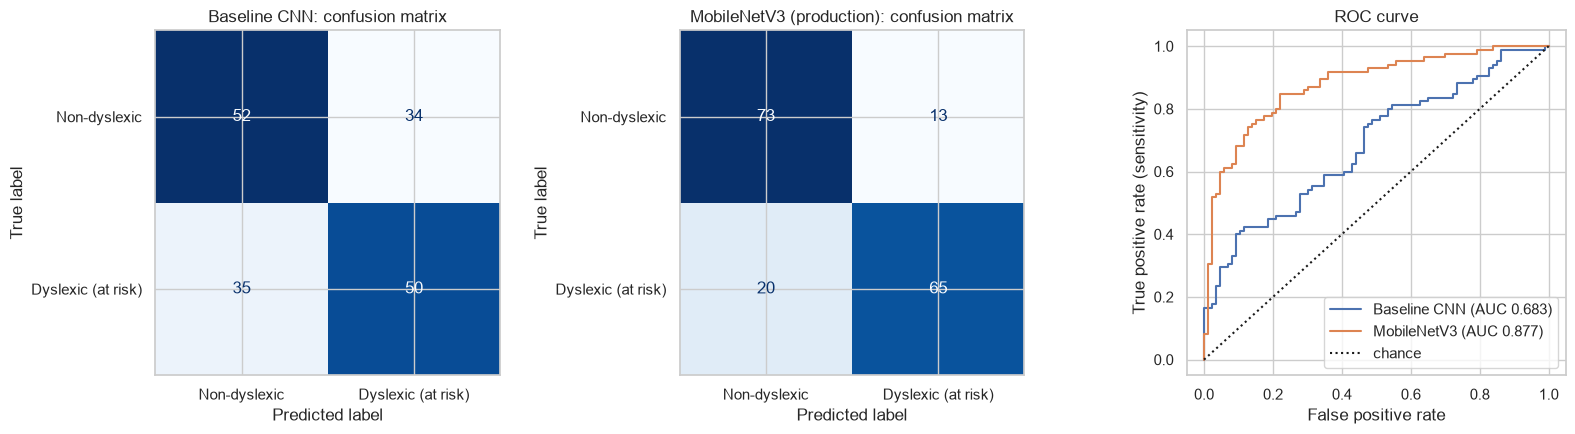

,precision,recall,f1-score,support
Non-dyslexic,0.785,0.849,0.816,86.000
Dyslexic (at risk),0.833,0.765,0.798,85.000
accuracy,0.807,0.807,0.807,0.807
macro avg,0.809,0.807,0.807,171.000
weighted avg,0.809,0.807,0.807,171.000


In [12]:
names = [CLASS_NAMES[0], CLASS_NAMES[1]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (title, m) in zip(axes[:2], [("Baseline CNN", base_metrics), ("MobileNetV3 (production)", prod_metrics)]):
    ConfusionMatrixDisplay(np.array(m["confusion_matrix"]), display_labels=names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}: confusion matrix")
for title, m in [("Baseline CNN", base_metrics), ("MobileNetV3", prod_metrics)]:
    fpr, tpr, _ = roc_curve(m["_y_true"], m["_probs"])
    axes[2].plot(fpr, tpr, label=f"{title} (AUC {m['roc_auc']:.3f})")
axes[2].plot([0, 1], [0, 1], "k:", label="chance")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate (sensitivity)")
axes[2].set_title("ROC curve"); axes[2].legend()
plt.tight_layout(); plt.show()

pd.DataFrame(prod_metrics["classification_report"]).T.round(3)

### 5.1 Screening threshold

A screening tool should miss as few at-risk children as possible. A false alarm only costs a teacher's follow-up, while a missed child can fall behind for years. The default threshold is 0.5; the table below shows how sensitivity and specificity trade off if a school wanted to catch more children.

In [13]:
y, p = np.array(prod_metrics["_y_true"]), np.array(prod_metrics["_probs"])
rows = []
for t in (0.3, 0.4, 0.5, 0.6):
    pred = (p >= t).astype(int)
    rows.append({"threshold": t,
                 "sensitivity (at-risk caught)": (pred[y == 1] == 1).mean(),
                 "specificity": (pred[y == 0] == 0).mean(),
                 "flagged share": pred.mean()})
pd.DataFrame(rows).round(3)

,threshold,sensitivity (at-risk caught),specificity,flagged share
0,0.3,0.847,0.733,0.556
1,0.4,0.824,0.779,0.520
2,0.5,0.765,0.849,0.456
3,0.6,0.753,0.860,0.444


### 5.2 How good is the model?

* The transfer-learning model clearly beats both the hand-crafted features (single-feature AUC ≈ 0.5) and the CNN trained from scratch. Learning letter *shape* is what carries the signal.
* The classes are balanced, so accuracy is meaningful here. We still report macro-F1, sensitivity and specificity, because in a real classroom only about 5–10 % of children have dyslexia.
* **Limitations (stated honestly):**
  * The dataset has no per-child IDs, so the same child's letters can appear in both train and test. That can make the test score look **better** than it would be on brand-new children.
  * The script mix (English / Urdu / digits) is not identical between the two groups, so part of the signal could come from *which* character was written rather than *how*.
  * One character is weak evidence. A real screen would combine many characters per child.
  * Only 852 images from one region; results may not transfer to other schools or alphabets.

## 6. Prediction function: one image

dyslexic_0086.png -> Dyslexic (at risk) {'Non-dyslexic': 0.008, 'Dyslexic (at risk)': 0.992}
non_dyslexic_0000.png -> Non-dyslexic {'Non-dyslexic': 0.929, 'Dyslexic (at risk)': 0.071}


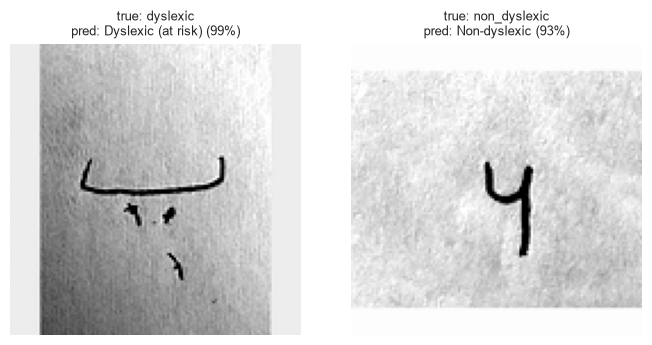

In [14]:
from src.prediction import predict_path

samples = [next((TEST_DIR / "dyslexic").glob("*.png")), next((TEST_DIR / "non_dyslexic").glob("*.png"))]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, path in zip(axes, samples):
    pred = predict_path(path)
    ax.imshow(load_image(path), cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {path.parent.name}\npred: {pred['label']} ({pred['confidence']:.0%})", fontsize=9)
    print(path.name, "->", pred["label"], {k: round(v, 3) for k, v in pred["probabilities"].items()})
plt.tight_layout(); plt.show()

## 7. Retraining and its trigger

How retraining works in production (`src/retrain.py`, `api/main.py`):

1. **Upload:** a user uploads a zip of class folders or many labelled images (`POST /upload-data`). Each image is validated, preprocessed and saved into `data/train/<class>/` and into the pending queue `data/uploads/`.
2. **Trigger:**
   * *manual:* the **Trigger retraining** button (`POST /retrain`);
   * *automatic:* once ≥ `RETRAIN_MIN_NEW_SAMPLES` (20) new images are pending, the API recommends retraining, and if `AUTO_RETRAIN=true` it starts one by itself.
3. **Retrain:** the current production model is the **warm-start / pre-trained starting point**. It is fine-tuned on the enlarged training set with a lower learning rate.
4. **Quality gate:** the candidate is evaluated on the held-out test set and **promoted only if macro-F1 does not drop by more than 0.02**. Otherwise the old model stays live.
5. **Hot reload:** every API replica notices the new model file and reloads it with no restart. The upload queue is archived so the trigger resets.

Below, the retraining function runs exactly as the API would run it.

In [15]:
from src.retrain import count_uploads, should_retrain
from src.config import RETRAIN_MIN_NEW_SAMPLES, AUTO_RETRAIN

print(f"Pending uploads: {count_uploads()} / threshold {RETRAIN_MIN_NEW_SAMPLES} -> retrain recommended: {should_retrain()}")
print("AUTO_RETRAIN:", AUTO_RETRAIN)

retrain_result = run_training(epochs=4, retrain=True)
print("mode:", retrain_result["mode"], "| promoted:", retrain_result["promoted"])
pd.DataFrame({"before": retrain_result["previous_metrics"],
              "after (candidate)": {k: retrain_result["metrics"][k] for k in retrain_result["previous_metrics"]}}).round(3)

Pending uploads: 0 / threshold 20 -> retrain recommended: False
AUTO_RETRAIN: False


Warm start from C:\Users\HP Spectre\Projects\alu-ml-summative-diabetes\models\dyslexia_cnn.pt


epoch  1/4  loss=0.154 acc=0.938  val_loss=0.503 val_acc=0.804 val_f1=0.803


epoch  2/4  loss=0.144 acc=0.950  val_loss=0.552 val_acc=0.804 val_f1=0.803


epoch  3/4  loss=0.120 acc=0.952  val_loss=0.558 val_acc=0.804 val_f1=0.803


epoch  4/4  loss=0.099 acc=0.967  val_loss=0.585 val_acc=0.833 val_f1=0.833


mode: retrain | promoted: True


,before,after (candidate)
accuracy,0.807,0.813
precision_macro,0.809,0.814
recall_macro,0.807,0.813
f1_macro,0.807,0.813
sensitivity_at_risk,0.765,0.788
specificity,0.849,0.837
roc_auc,0.877,0.875


## 8. Deployment and load testing

Not run inside this notebook. See the README for:
* the FastAPI service (`uvicorn api.main:app`) and Streamlit UI (`streamlit run ui/app.py`);
* Docker (`docker compose up --build --scale api=N`) behind an nginx load balancer;
* the Locust flood test (`locust/locustfile.py`) with latency results for 1, 2 and 3 containers.